# Defense evaluation: Dummy Actuations

* load pretrained DRQN attack agent
* generate a true protocol
* search a Pareto front of defenses for it (`run_defense.py`)
* pick a defense schedule from the saved front
* run multipass refinement with the attack agent, once undefended and once with the defense's dummy actuations active

**necessary imports:**

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))                     # repo root: defense.NSGA_II_utils.*
sys.path.insert(0, os.path.abspath('../environment_utils'))   # Env, CustomFeatureExtractor, helper_functions, protocol_creation
sys.path.insert(0, os.path.abspath('./RL_agent_utils'))       # attack_agent, multipass_refinement, plot_3d

import numpy as np
import gymnasium as gym

from attack_agent import DRQNagent
from Env import VoltageDistributionEnv
from CustomFeatureExtractor import CustomFeatureExtractor
from belief_state import BeliefStateMap
from multipass_refinement import extract_qvalues, PassBasedMasking, MultipassEnvWrapper
from plot_3d_entropy import plot_3d_entropy_path

from protocol_creation import intelligent_walk
import defense.NSGA_II_utils.config as config
import defense.NSGA_II_utils.evolve as evolve
import defense.NSGA_II_utils.field as field
import defense.NSGA_II_utils.genome as genome
import defense.NSGA_II_utils.visualize as visualize
import run_defense

/Users/biplovebaral/Desktop/Droplet_Research/Droplet_Tracker_Modularized/official_repo/RRDQNvenv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## 1. Load pretrained attack agent (no training)

In [2]:
loaded_agent = DRQNagent.load_complete(
    '../models/RecurrentDQN_Finalized_11x11_V3_PT2.pkl',  # 11x11 model to match grid_configuration.json
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

Complete agent loaded from: ../models/RecurrentDQN_Finalized_11x11_V3_PT2.pkl
Trained for 100018 steps, 3263 episodes


## 2. Generate droplet protocol

In [10]:
protocol = [ tuple(cell) for cell in intelligent_walk(config.OBSTACLES, config.VISIT_POINTS, config.RESERVOIRS, config.GRID_SIZE)]
print(f"protocol: {len(protocol)} timesteps, {protocol[0]} -> {protocol[-1]}")

protocol: 37 timesteps, (9, 1) -> (9, 9)


## 3. Search the Pareto front of defenses for this protocol

Same `run_defense.py` used from the command line, just handed our protocol instead of a random one.
Saves `last_run.npz` and `pareto_front.csv`, same as the CLI.

In [11]:
protocol_args = ' '.join(str(v) for cell in protocol for v in cell)
!python3 run_defense.py --protocol {protocol_args}

protocol: 37 timesteps, (9, 1) to (9, 9)
searching (pop 1000, 50 generations)...

search took 184.7s
population 1000 -> 699 non-dominated (Pareto-optimal) out of it
saved last_run.npz, pareto_front.csv

all 3 columns are [0,1], lower is better on every one
                      min   median      max
           count    0.024    0.275    0.568
          spread    0.001    0.209    0.929
 attack_accuracy    0.320    0.503    0.716

full table in pareto_front.csv; run `python run_defense.py --pick <index>` to render one
opening interactive 3D plot (close the window to exit)...
Figure(800x700)


since jupyternotebook is weird about showing plots (can't open a subfigure), run the cell above and then run the following commands in the terminal. 
* `python3 run_defense.py --front`
* `python3 run_defense.py --pick 1`, can exchange 1 with index of choice. 


## 4. Visualize Pareto front of defenses

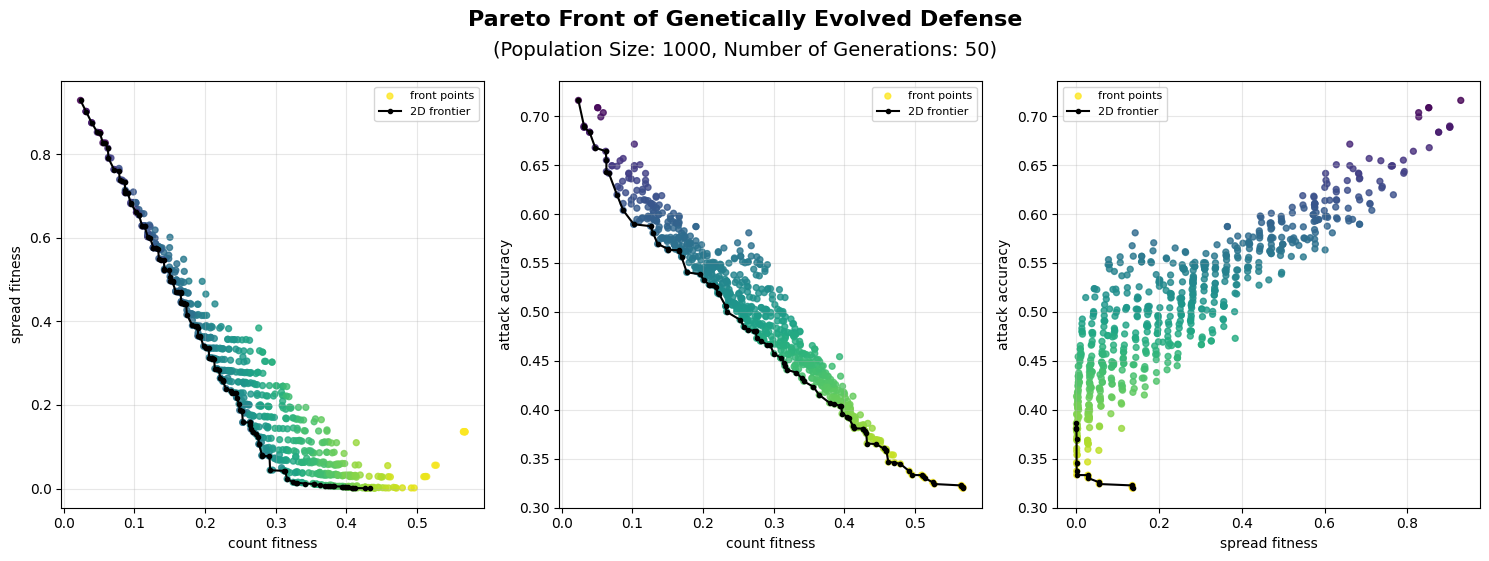

In [12]:
_, X, F = evolve.load_run('last_run.npz')
visualize.plot_pareto_slices(F, config.POP_SIZE, config.N_GEN)
# relabel this as, need a color bar for left hand plot and don't need middle or left plot. Linear way, we want to exponentite the x-axis. 
# cost, we are minimize for spread is not clear
# whats the cost for spread, spread is not the best way to describe this? 
# another way to define spread -> take grid size, remove the number of electrodes in the barrier, then remove the possible area each way for dummy actuations (8), normalize that to the grid.
# labeling this as not as spread but as the amount of available routing space for multidroplet routing. 
# maximize amount of area available and minimize the cost. Minimize the cost of dummy area.  

## 5. Check Defense against RL agent 

Pick an index off the front above, decode it into a schedule, and run the agent through 3 passes of the same protocol. 

Alongside the agent's own belief, a second "ground-truth" belief is tracked: every probe is fed `real_field(true_droplet)[probe]`, so the real droplet's own EMF at that electrode, regardless of any
dummy contribution mixed into what the agent actually saw. 

In [13]:
class DefenseMultipassEnvWrapper(MultipassEnvWrapper):
    """
    Same 3-pass refinement as MultipassEnvWrapper, but every pass uses our fixed protocol and injects the schedule's combined real+dummy EMF into what the agent actually observes.
    """

    def __init__(self, env, pass_based_masking, pass_num, schedule, protocol):
        super().__init__(env, pass_based_masking, pass_num, stored_protocol=protocol)
        self.schedule = schedule
        self.ground_truth_belief = BeliefStateMap(env.size, env.belief.sigma, env.belief.threshold)
        self.ground_truth_entropy = []

    def _apply_defense(self):
        """
        Overwrite the env's voltage grid for the current droplet position with the combined (real+dummy) field, so the next measurement reflects the defense.
        """
        t = self.env._droplet_path_index
        true_cell = tuple(self.env._droplet_location)
        dummies = self.schedule[t] if t < len(self.schedule) else []
        self.env._voltage_grid = field.combined_field(true_cell, dummies)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)

        self.env._droplet_path = self.stored_protocol
        self.env._droplet_path_index = 0
        self.env._droplet_location = self.env._droplet_path[0]
        self.env.end_pos = self.env._droplet_path[-1]
        self.env.length = len(self.env._droplet_path)
        self._apply_defense()

        if self.pass_num > 1:
            refined_mask = self.pass_based_masking.get_refined_mask(timestep=0, current_belief_mask=info['action_mask'])
            info['action_mask'] = refined_mask

        self.timestep = 0
        self.pass_based_masking.start_new_episode()

        self.ground_truth_belief.reset()
        self.ground_truth_entropy = []

        return obs, info

    def step(self, action):
        t = self.timestep
        true_cell = tuple(self.env._droplet_location)  # droplet's position for timestep t, before it advances

        obs, reward, terminated, truncated, info = super().step(action)

        probe = (action // self.grid_size, action % self.grid_size)
        measurement = field.real_field(true_cell)[probe]
        self.ground_truth_belief.prediction()
        self.ground_truth_belief.correction(measurement=measurement, probe_position=probe)
        self.ground_truth_entropy.append(self.ground_truth_belief.get_state_entropy())

        self._apply_defense()  # prep the next timestep's combined field before the next step() call
        return obs, reward, terminated, truncated, info

In [14]:
def run_defense_multipass(agent, protocol, schedule, num_passes=3):
    """
    Same 3-pass loop as run_multipass_protocol, but through DefenseMultipassEnvWrapper
    """
    pass_based_masking = PassBasedMasking(config.GRID_SIZE)
    ground_truth_entropy = {}

    for pass_num in range(1, num_passes + 1):
        base_env = VoltageDistributionEnv()
        env = DefenseMultipassEnvWrapper(base_env, pass_based_masking, pass_num, schedule, protocol)

        obs, info = env.reset()
        hidden = None
        done = False

        while not done:
            action_mask = info.get('action_mask', None)
            q_values, hidden = extract_qvalues(agent, obs, hidden)

            if action_mask is not None:
                valid_indices = np.where(np.array(action_mask) == 1)[0]
                action = valid_indices[np.argmax(q_values[valid_indices])] if len(valid_indices) else np.argmax(q_values)
            else:
                action = np.argmax(q_values)

            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

        if pass_num == 1 or pass_num == num_passes:
            ground_truth_entropy[pass_num] = list(env.ground_truth_entropy)

    return ground_truth_entropy

In [15]:
idx = int(input(f"pick a Pareto point index (0 to {len(F) - 1}): "))
schedule = genome.decode(X[idx], protocol)
results = run_defense_multipass(loaded_agent, protocol, schedule)

empty_schedule = [[] for _ in protocol]
undefended_results = run_defense_multipass(loaded_agent, protocol, empty_schedule)

print(f"average entropy -- undefended: pass 1: {np.mean(undefended_results[1]):.3f}   pass 3: {np.mean(undefended_results[3]):.3f}")
print(f"average entropy -- defended:   pass 1: {np.mean(results[1]):.3f}   pass 3: {np.mean(results[3]):.3f}")

average entropy -- undefended: pass 1: 0.111   pass 3: 0.004
average entropy -- defended:   pass 1: 0.178   pass 3: 0.150


## 6. Visualization 

**entropy plots at each timestep for defended and undefended protocol**

**Entropy of undefended protocol**


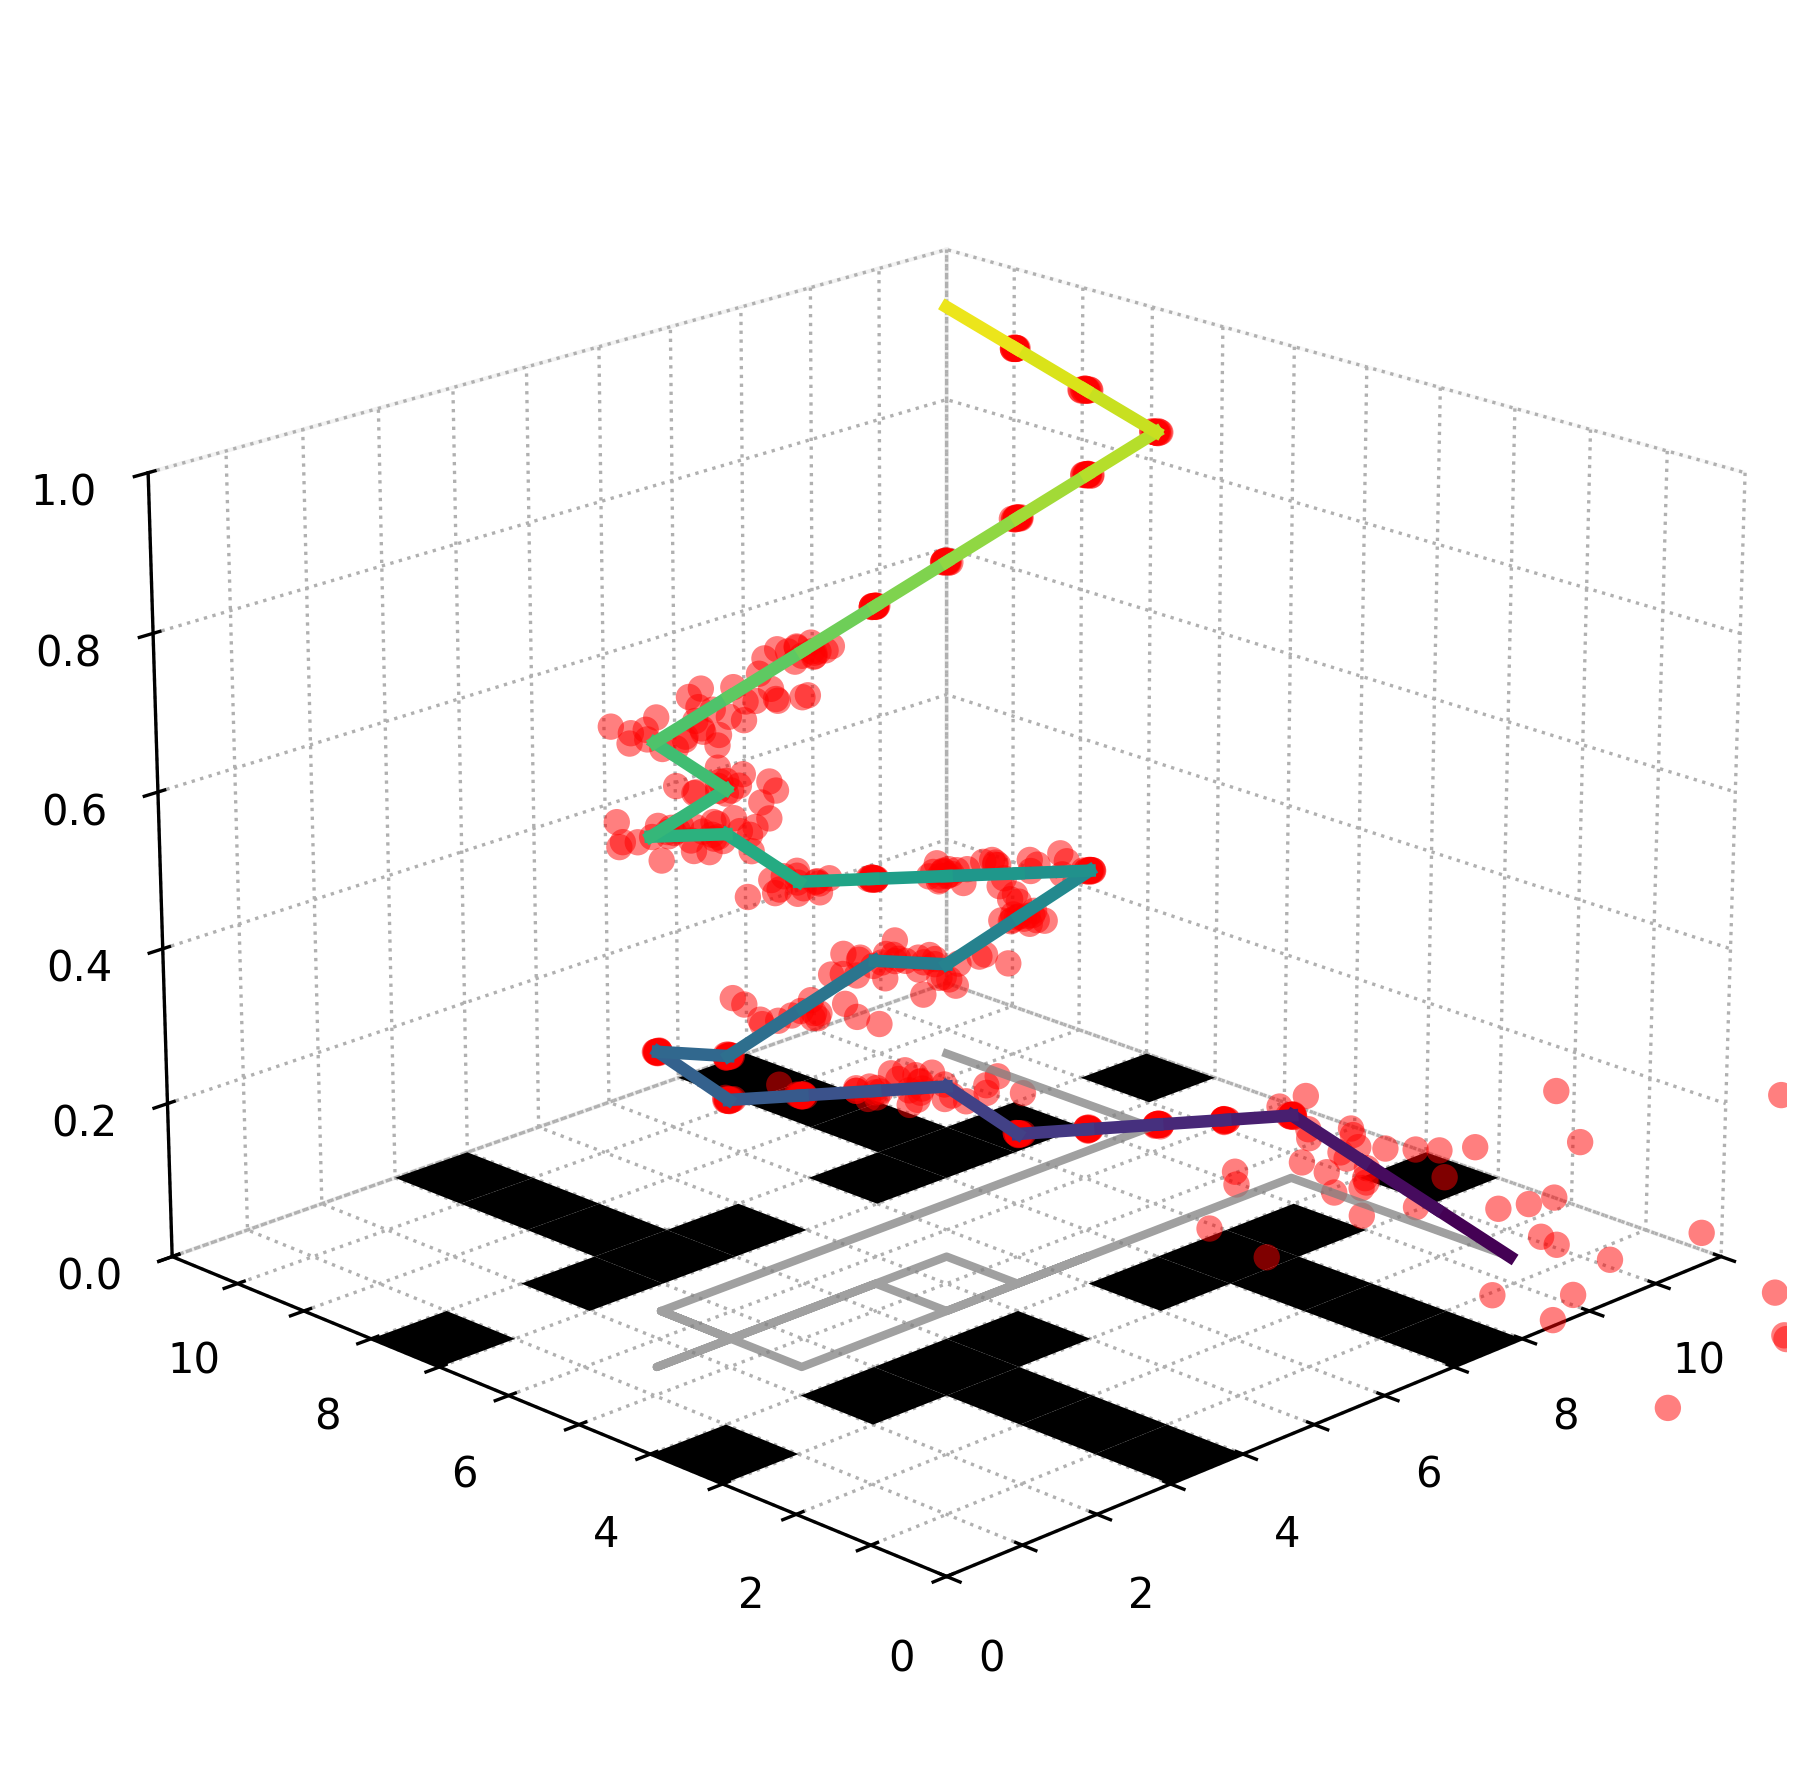

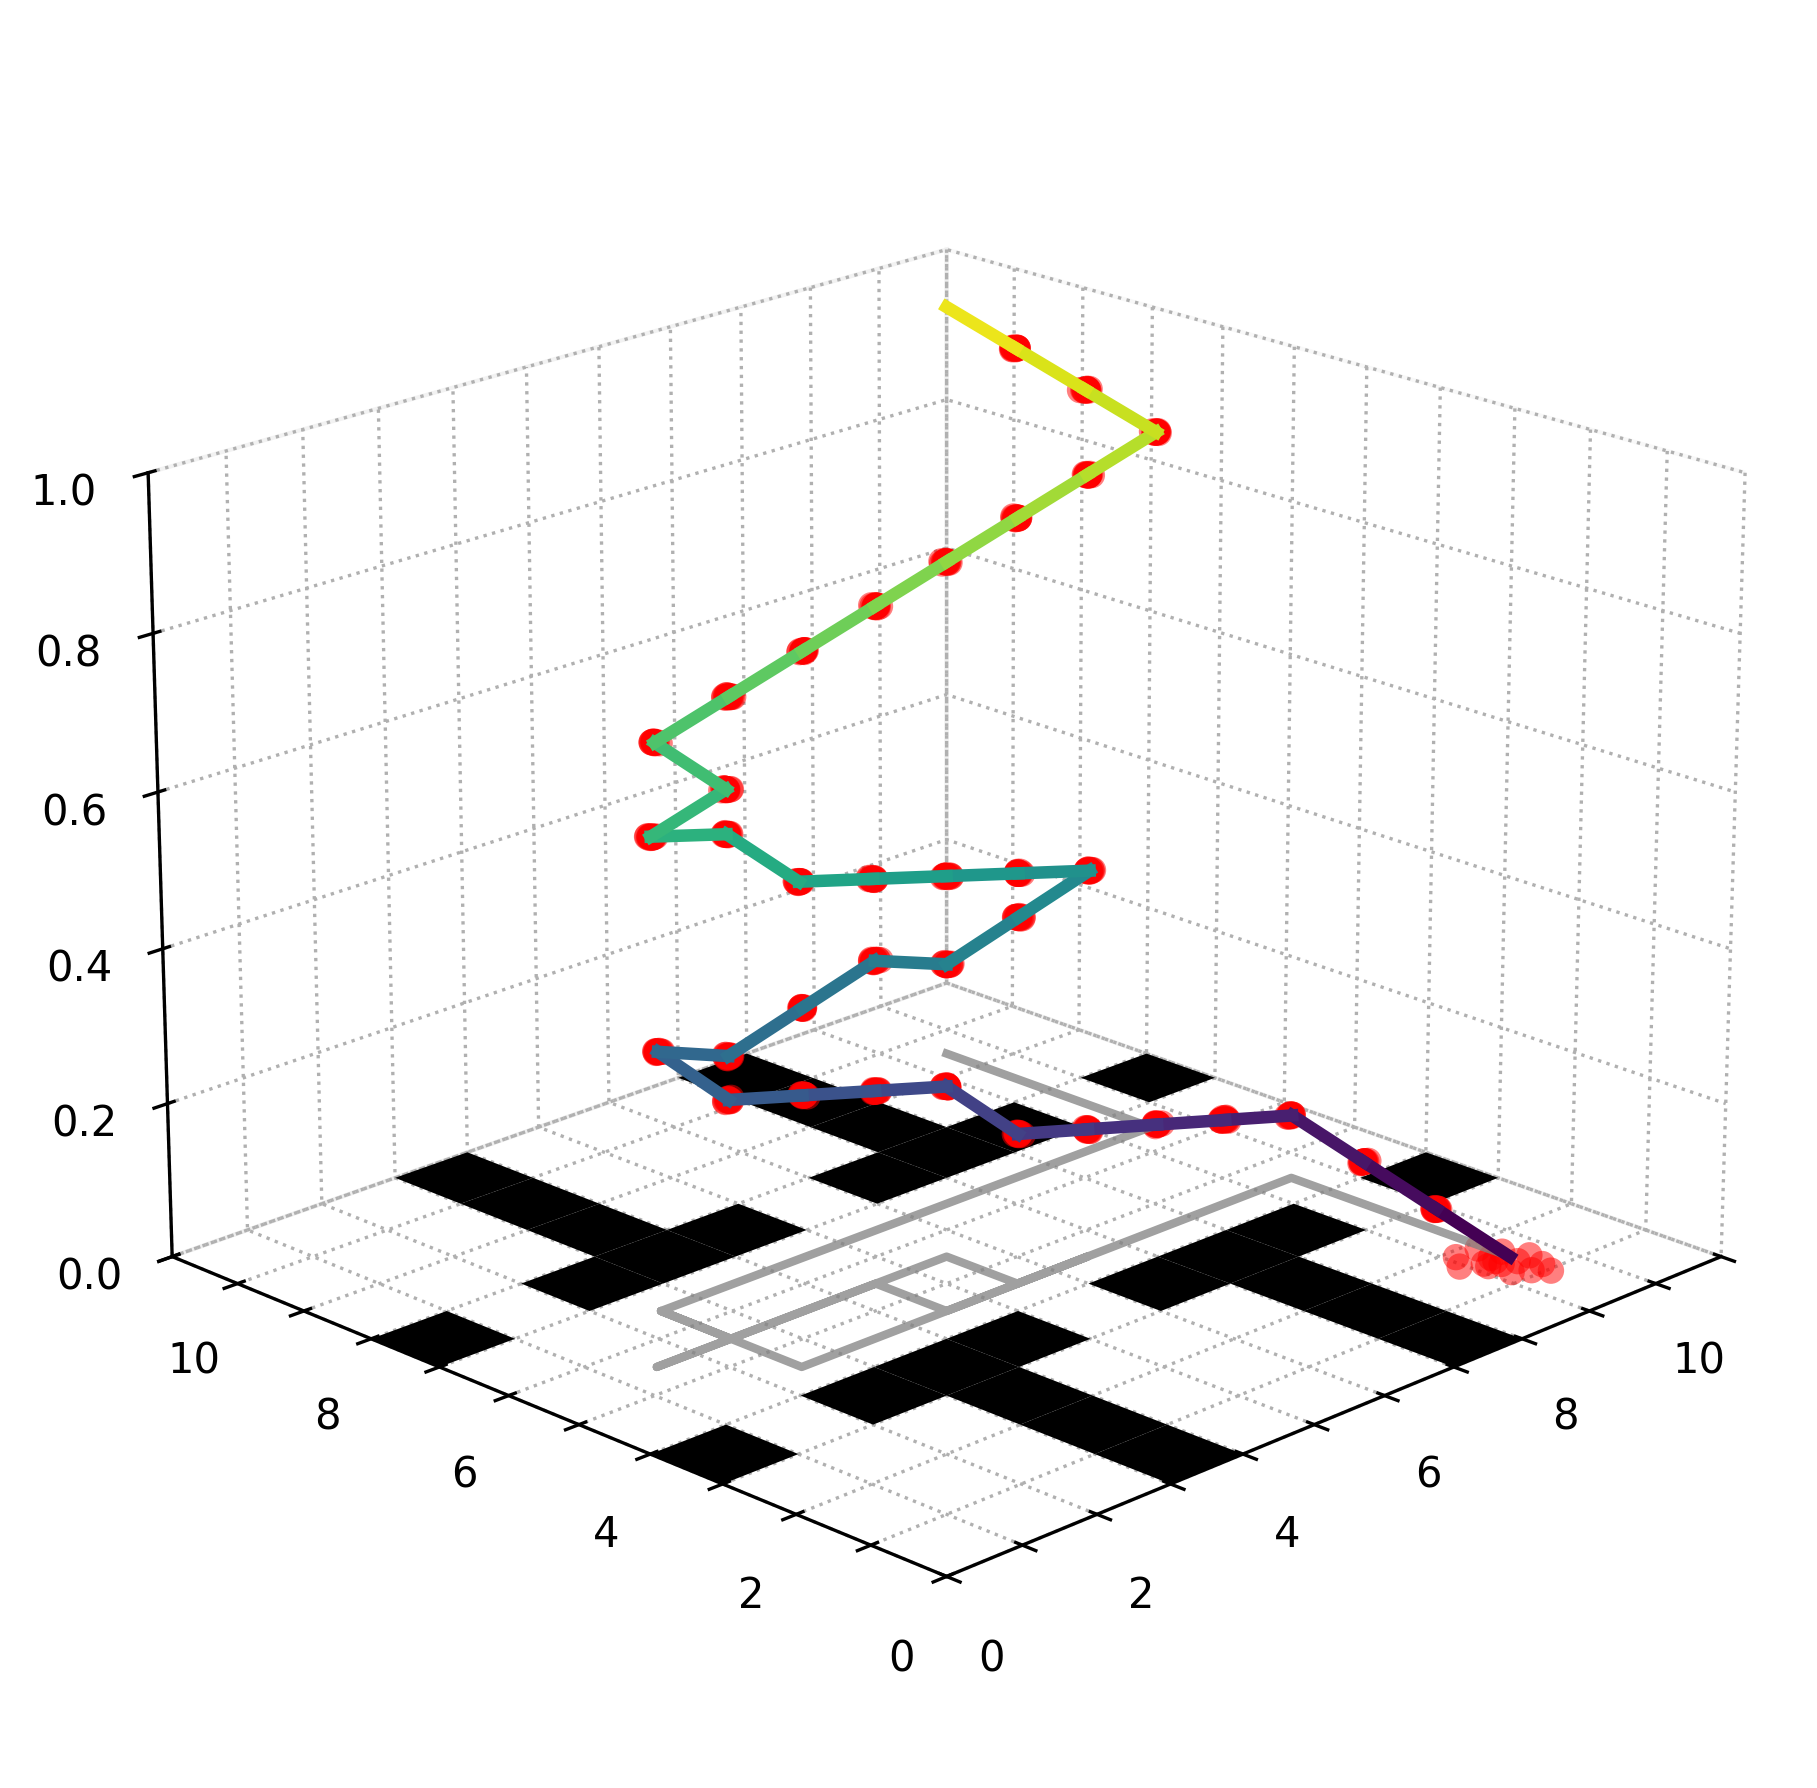

In [16]:
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, undefended_results[1])
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, undefended_results[3])

**Entropy of defended protocol**

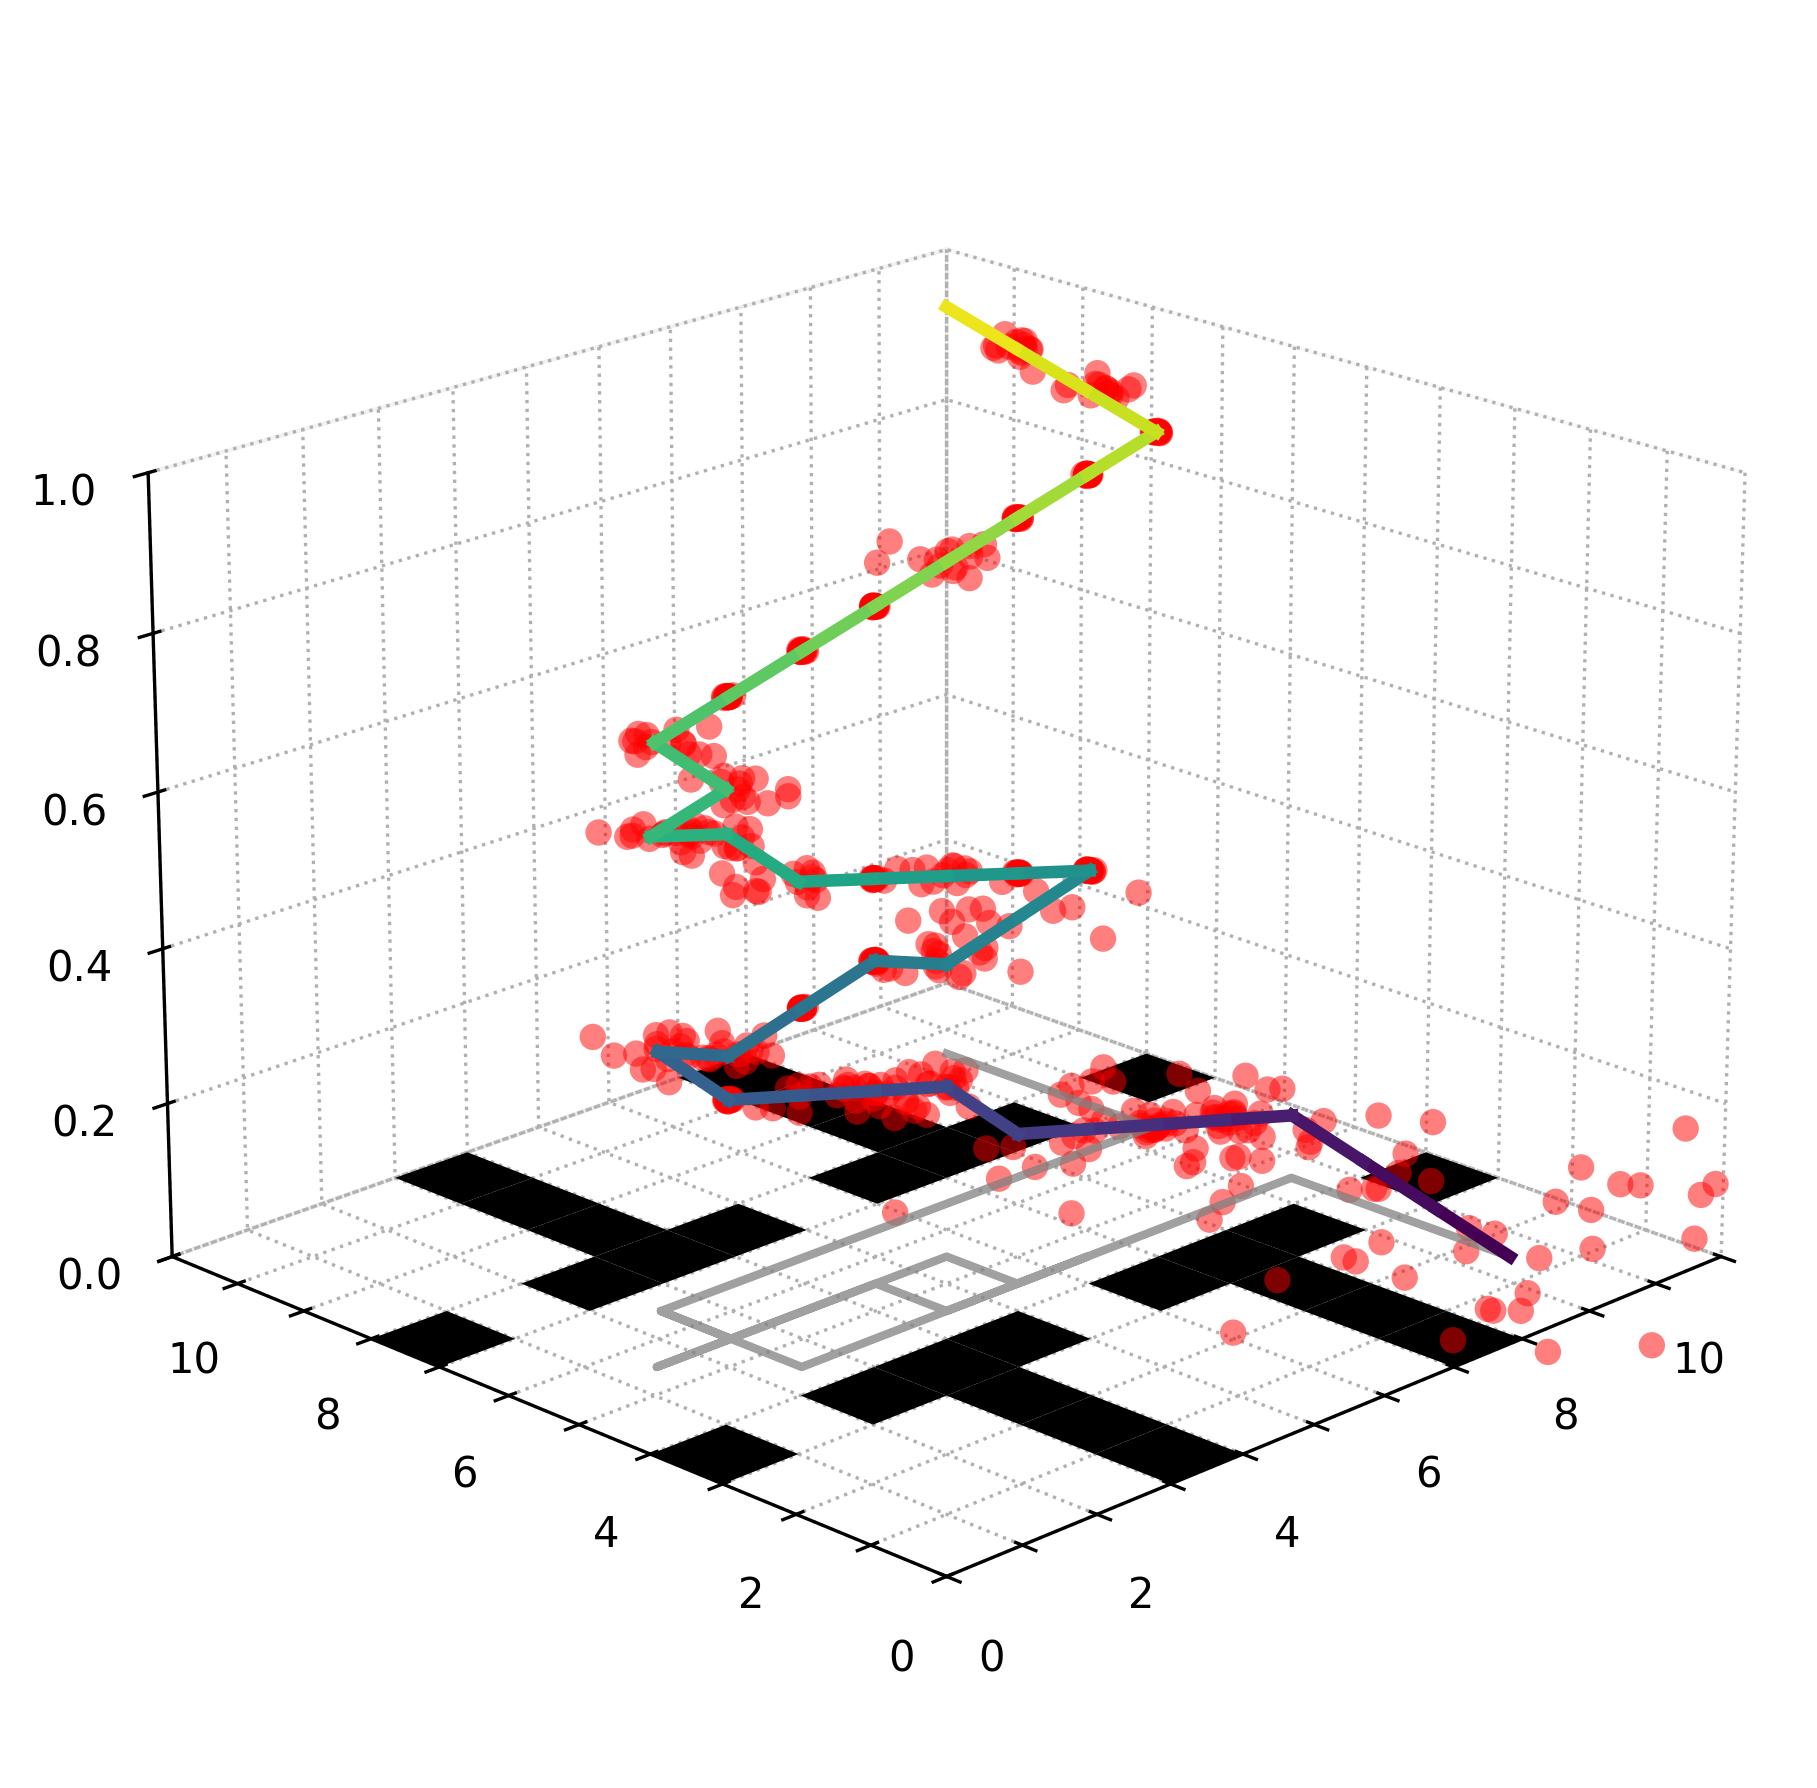

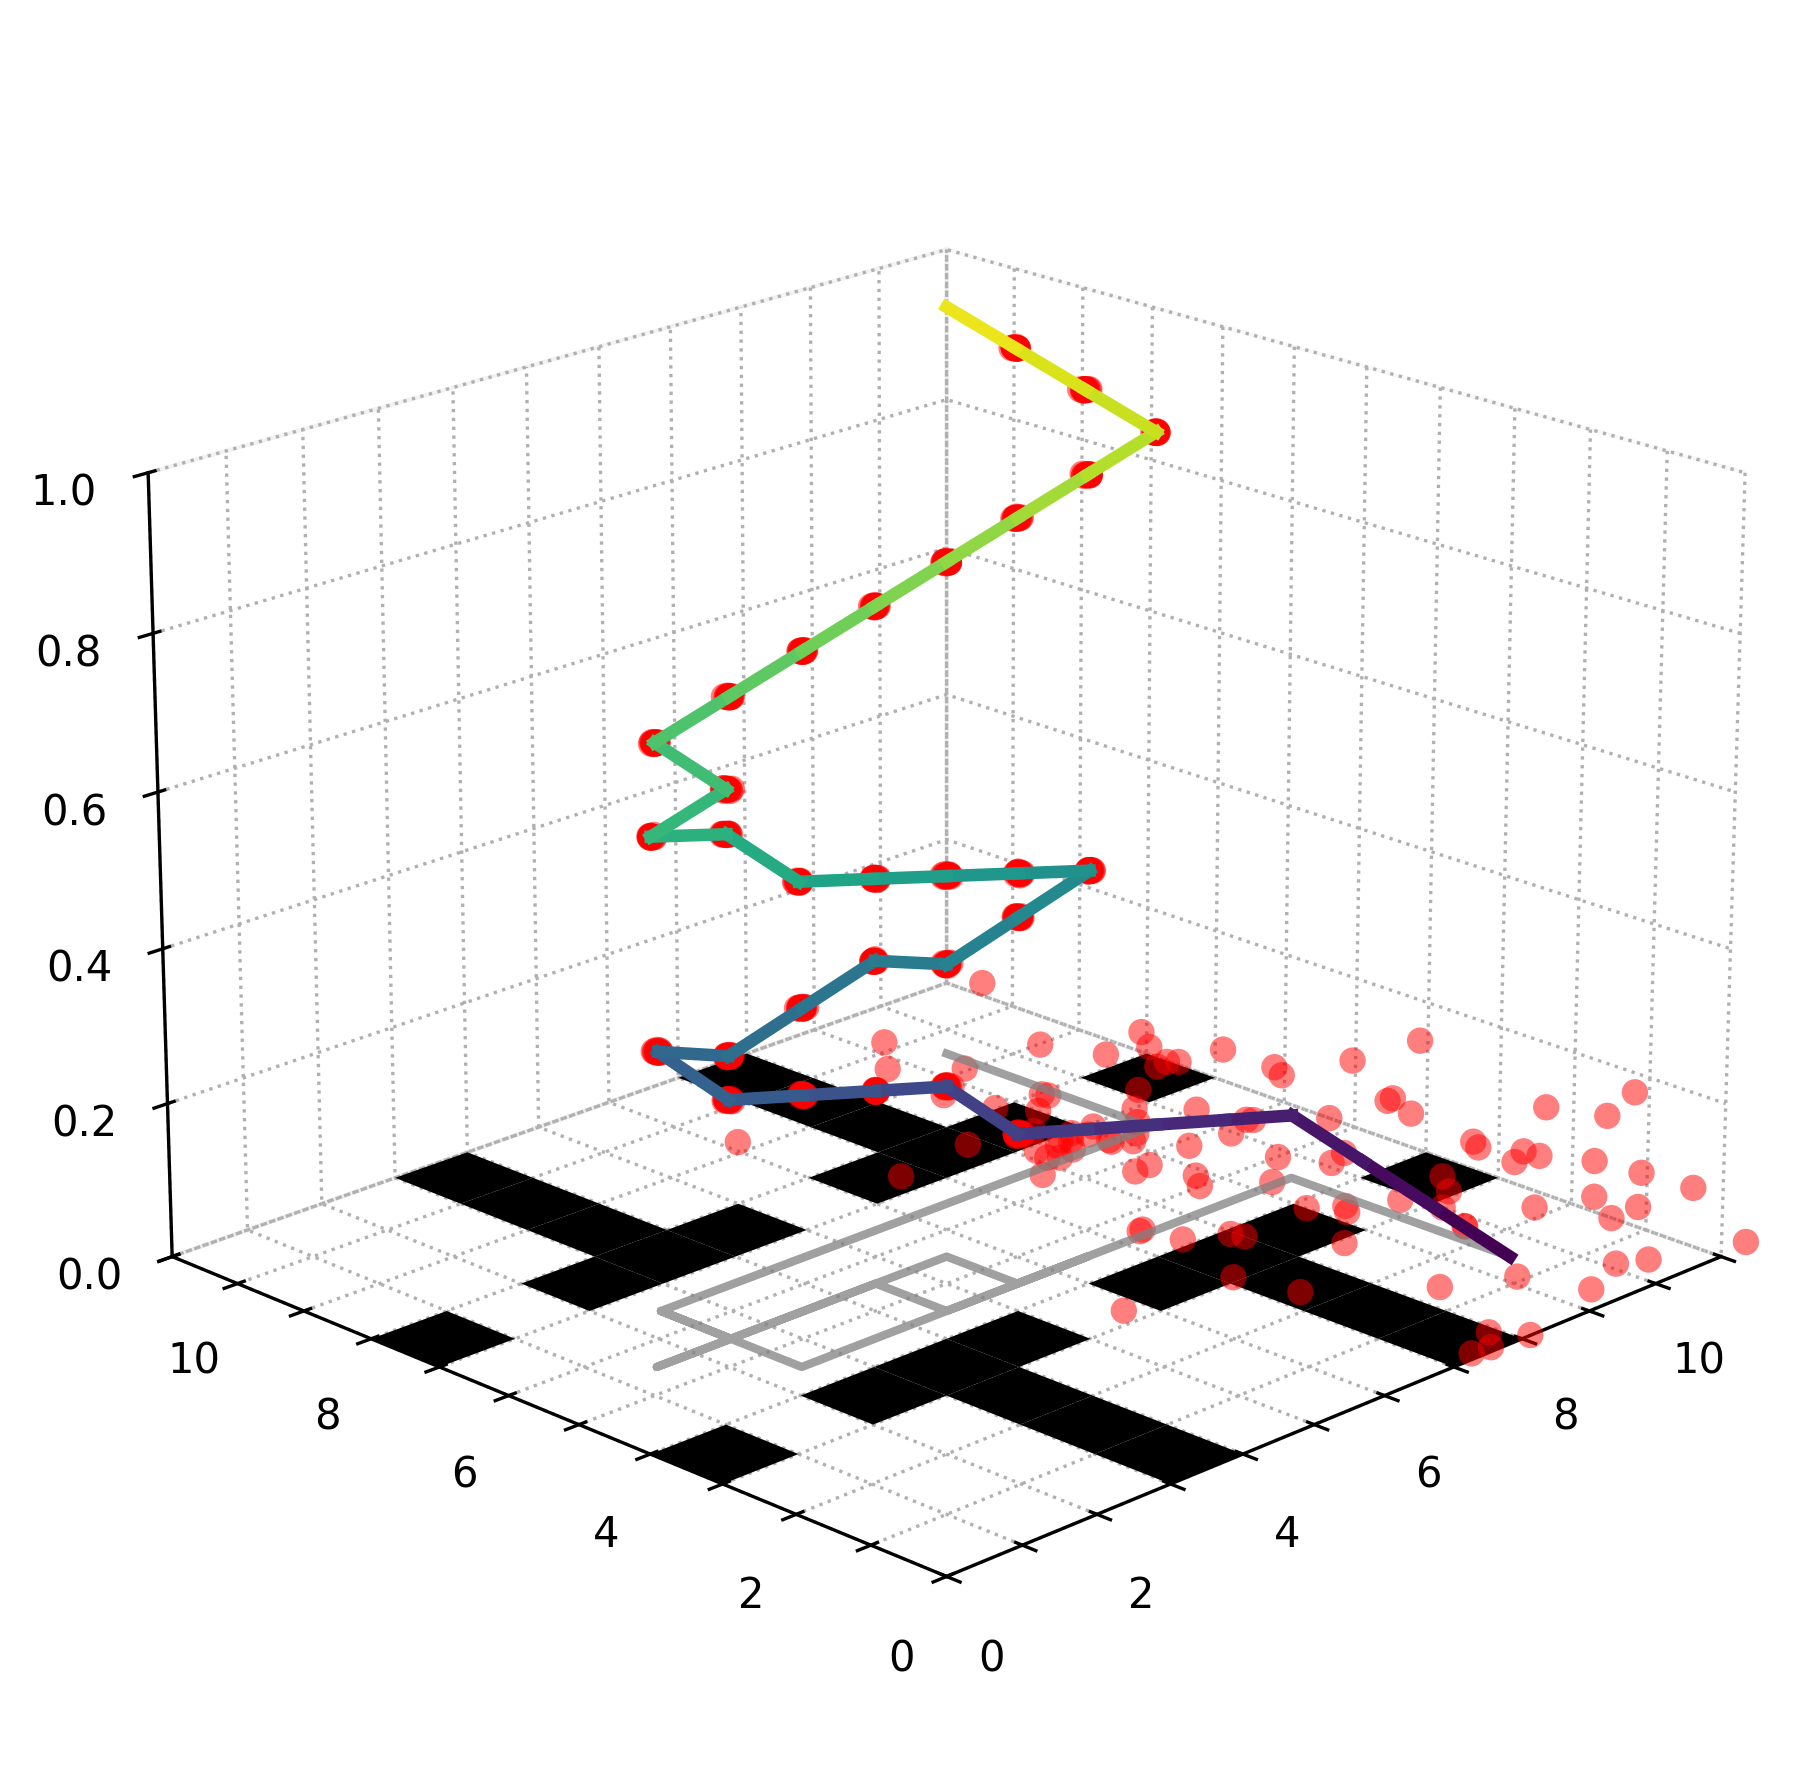

In [17]:
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, results[1])
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, results[3])